# WHEN NATURE STRIKES
## 03 – Temporal Trends Analysis

### 1. Introduction

This analysis examines how natural disaster occurrence
and their impacts have changed over time.

The objective is to identify long-term patterns,
compare disaster frequency across decades and investigate
changes in human and economic consequences.

### 2. Research Questions

1. How has natural disaster frequency changed over time?
2. Which decades recorded the highest disaster frequency?
3. How have reported deaths changed across decades?
4. How has the affected population changed over time?
5. How have inflation-adjusted economic losses evolved?
6. Are there differences between historical and recent records?

### 3. Dataset

- Primary dataset: natural_disaster_events.csv
- Source: EM-DAT, CRED / UCLouvain
- Time coverage: 1900–2026
- Total unique events: 15,727

### 4. Methodology

- Group unique disaster events by Start Year.
- Calculate annual disaster frequency.
- Group events by Decade.
- Calculate decadal frequency and reported impacts.
- Compare deaths, affected population and adjusted damage.
- Examine reporting coverage across time periods.

### 5. Important Considerations

- Each event is counted only once.
- Missing impact values are not treated as zero.
- Economic damage uses inflation-adjusted million US dollars.
- Historical records before 2000 have lower reporting quality.
- The year 2026 is incomplete and should be interpreted cautiously.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 7)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
ROOT = Path.cwd()

if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed"

events = pd.read_csv(
    DATA_DIR / "natural_disaster_events.csv",
    encoding="utf-8-sig"
)

print("Dataset loaded successfully!")
print("Total events:", len(events))

Dataset loaded successfully!
Total events: 15727


In [4]:
# Convert year and decade columns to numeric

events["Start Year"] = pd.to_numeric(
    events["Start Year"],
    errors="coerce"
)

events["Decade"] = pd.to_numeric(
    events["Decade"],
    errors="coerce"
)

# Create a clean analysis dataset

time_data = events.dropna(
    subset=["Start Year", "Decade"]
).copy()

time_data["Start Year"] = time_data["Start Year"].astype(int)
time_data["Decade"] = time_data["Decade"].astype(int)

print("Earliest year:", time_data["Start Year"].min())
print("Latest year:", time_data["Start Year"].max())
print("Records available:", len(time_data))

Earliest year: 1900
Latest year: 2026
Records available: 15727


In [ ]:
#yearly disaster frequency

In [5]:
yearly_frequency = (
    time_data.groupby("Start Year")["Event ID"]
    .nunique()
    .reset_index(name="Unique Events")
)

display(yearly_frequency.head(10))

,Start Year,Unique Events
0,1900,7
1,1901,2
2,1902,10
3,1903,12
4,1904,4
5,1905,8
6,1906,11
7,1907,6
8,1908,3
9,1909,17


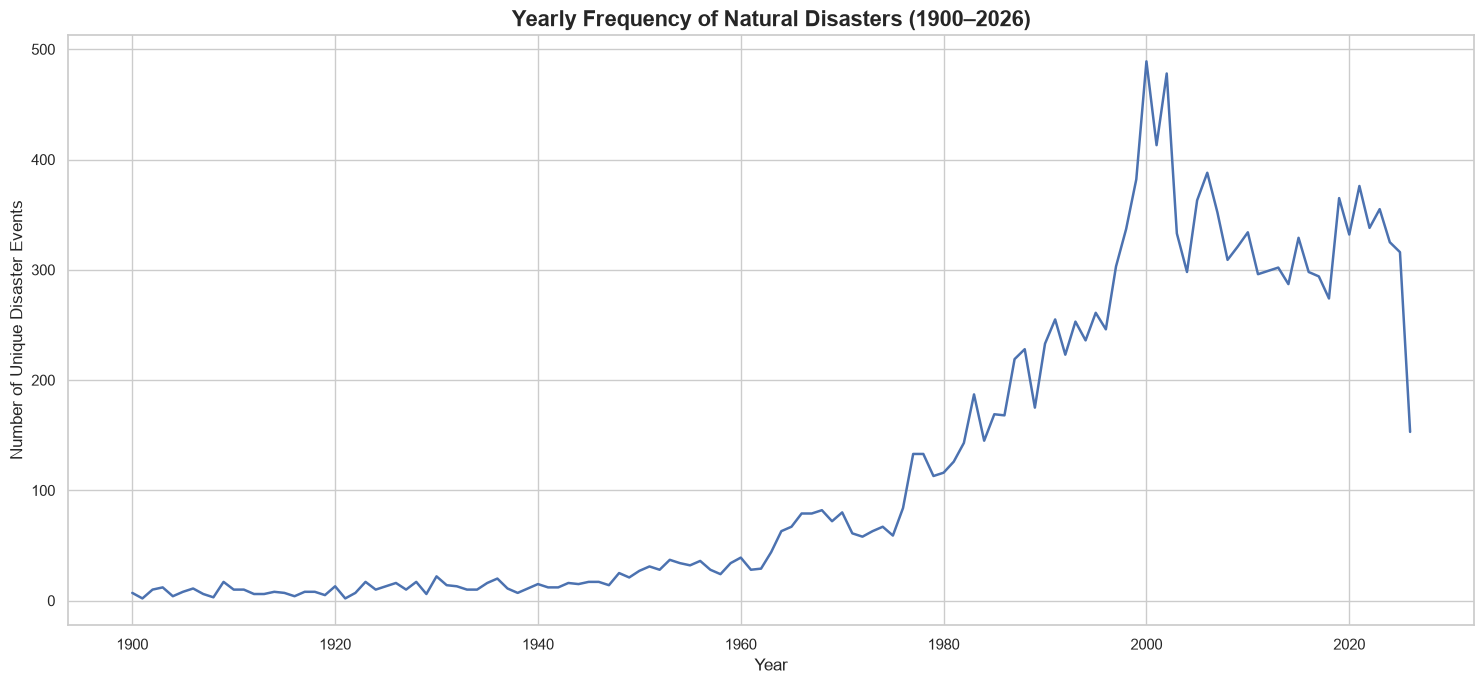

In [6]:
plt.figure(figsize=(15, 7))

sns.lineplot(
    data=yearly_frequency,
    x="Start Year",
    y="Unique Events",
    linewidth=1.8
)

plt.title(
    "Yearly Frequency of Natural Disasters (1900–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Number of Unique Disaster Events")

plt.tight_layout()

trend_dir = ROOT / "visualizations" / "trends"
trend_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    trend_dir / "01_yearly_disaster_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
#disaster frequency by decade

In [8]:
decadal_frequency = (
    time_data.groupby("Decade")["Event ID"]
    .nunique()
    .reset_index(name="Unique Events")
)

display(decadal_frequency)

,Decade,Unique Events
0,1900,80
1,1910,72
2,1920,111
3,1930,134
4,1940,164
5,1950,311
6,1960,582
7,1970,851
8,1980,1676
9,1990,2729


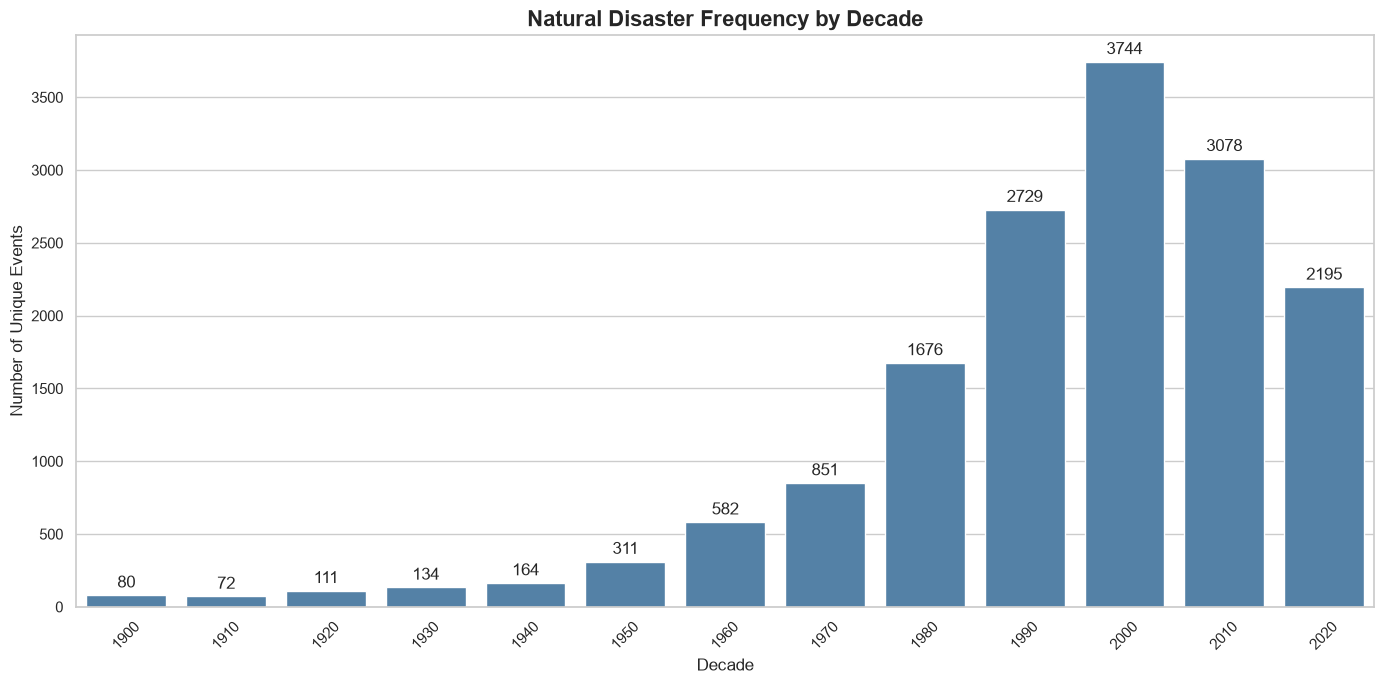

In [9]:
plt.figure(figsize=(14, 7))

ax = sns.barplot(
    data=decadal_frequency,
    x="Decade",
    y="Unique Events",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title(
    "Natural Disaster Frequency by Decade",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Decade")
plt.ylabel("Number of Unique Events")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    trend_dir / "02_decadal_disaster_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
top_decades = decadal_frequency.sort_values(
    "Unique Events",
    ascending=False
)

display(top_decades.head(5))

print(
    "Decade with highest recorded frequency:",
    top_decades.iloc[0]["Decade"]
)

,Decade,Unique Events
10,2000,3744
11,2010,3078
9,1990,2729
12,2020,2195
8,1980,1676


Decade with highest recorded frequency: 2000


In [11]:
#human impacts across decades

In [12]:
impact_columns = [
    "Total Deaths",
    "Total Affected",
    "Total Damage, Adjusted (million US$)"
]

decadal_impact = (
    time_data.groupby("Decade")
    .agg(
        Unique_Events=("Event ID", "nunique"),
        **{
            "Reported Death Events": (
                "Total Deaths", "count"
            ),
            "Total Deaths": (
                "Total Deaths",
                lambda x: x.sum(min_count=1)
            ),
            "Average Deaths": (
                "Total Deaths", "mean"
            ),
            "Reported Affected Events": (
                "Total Affected", "count"
            ),
            "Total Affected": (
                "Total Affected",
                lambda x: x.sum(min_count=1)
            ),
            "Average Affected": (
                "Total Affected", "mean"
            ),
            "Reported Damage Events": (
                "Total Damage, Adjusted (million US$)",
                "count"
            ),
            "Total Adjusted Damage": (
                "Total Damage, Adjusted (million US$)",
                lambda x: x.sum(min_count=1)
            ),
            "Average Adjusted Damage": (
                "Total Damage, Adjusted (million US$)",
                "mean"
            )
        }
    )
    .reset_index()
)

display(decadal_impact)

,Decade,Unique_Events,Reported Death Events,Total Deaths,Average Deaths,Reported Affected Events,Total Affected,Average Affected,Reported Damage Events,Total Adjusted Damage,Average Adjusted Damage
0,1900,80,73,4472682.0,61269.616438,24,6.211700e+05,2.588208e+04,17,50299.634,2958.802000
1,1910,72,62,3333790.0,53770.806452,21,6.341473e+06,3.019749e+05,15,14357.777,957.185133
2,1920,111,92,8562465.0,93070.271739,27,4.457725e+07,1.651009e+06,18,19124.988,1062.499333
3,1930,134,119,4644783.0,39031.789916,44,1.603763e+07,3.644915e+05,24,81355.086,3389.795250
4,1940,164,144,3879024.0,26937.666667,50,3.505979e+06,7.011958e+04,28,51850.391,1851.799679
5,1950,311,288,2136187.0,7417.315972,100,3.429491e+07,3.429491e+05,65,83317.039,1281.800600
6,1960,582,451,1751443.0,3883.465632,350,1.955009e+08,5.585739e+05,249,189363.496,760.495968
7,1970,851,616,998973.0,1621.709416,592,5.619404e+08,9.492236e+05,317,327487.619,1033.083972
8,1980,1676,1150,797079.0,693.112174,1116,1.245482e+09,1.116024e+06,557,596644.403,1071.174871
9,1990,2729,1973,528199.0,267.713634,2127,2.015844e+09,9.477405e+05,1027,1504650.016,1465.092518


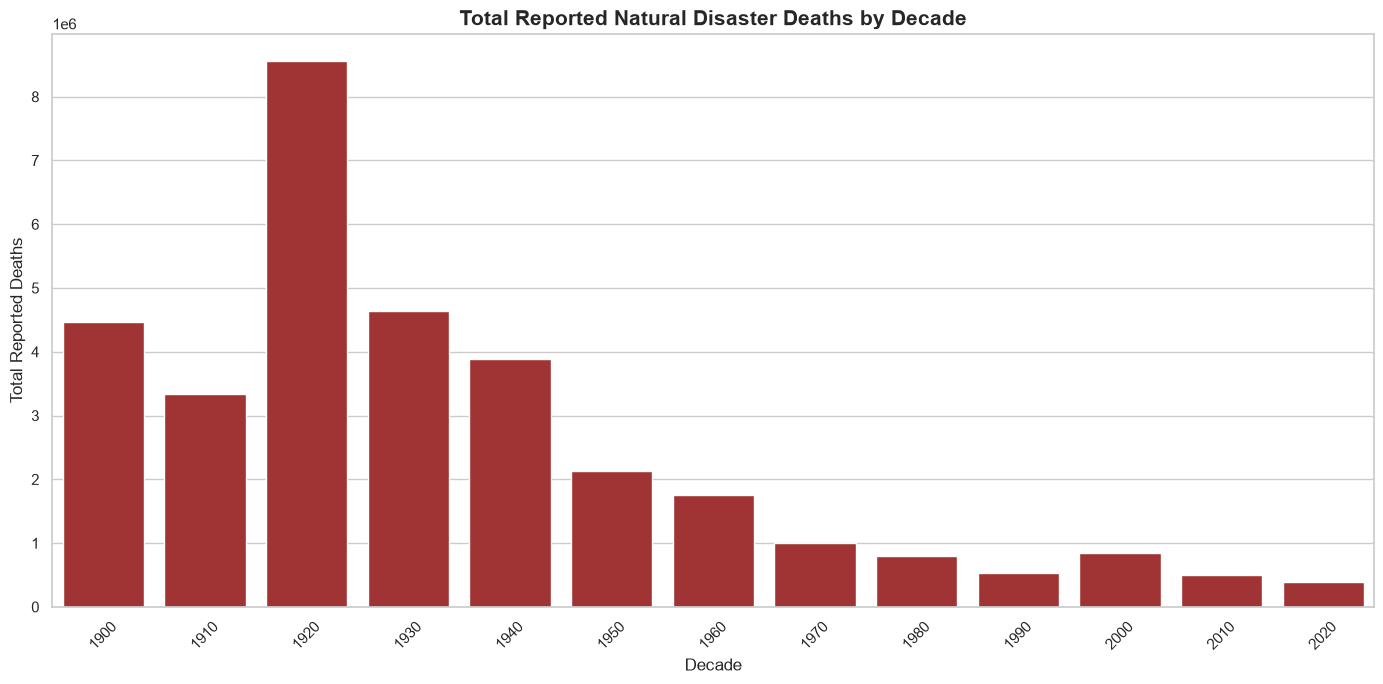

In [13]:
death_data = decadal_impact.dropna(
    subset=["Total Deaths"]
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=death_data,
    x="Decade",
    y="Total Deaths",
    color="firebrick"
)

plt.title(
    "Total Reported Natural Disaster Deaths by Decade",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Decade")
plt.ylabel("Total Reported Deaths")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    trend_dir / "03_decadal_deaths.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

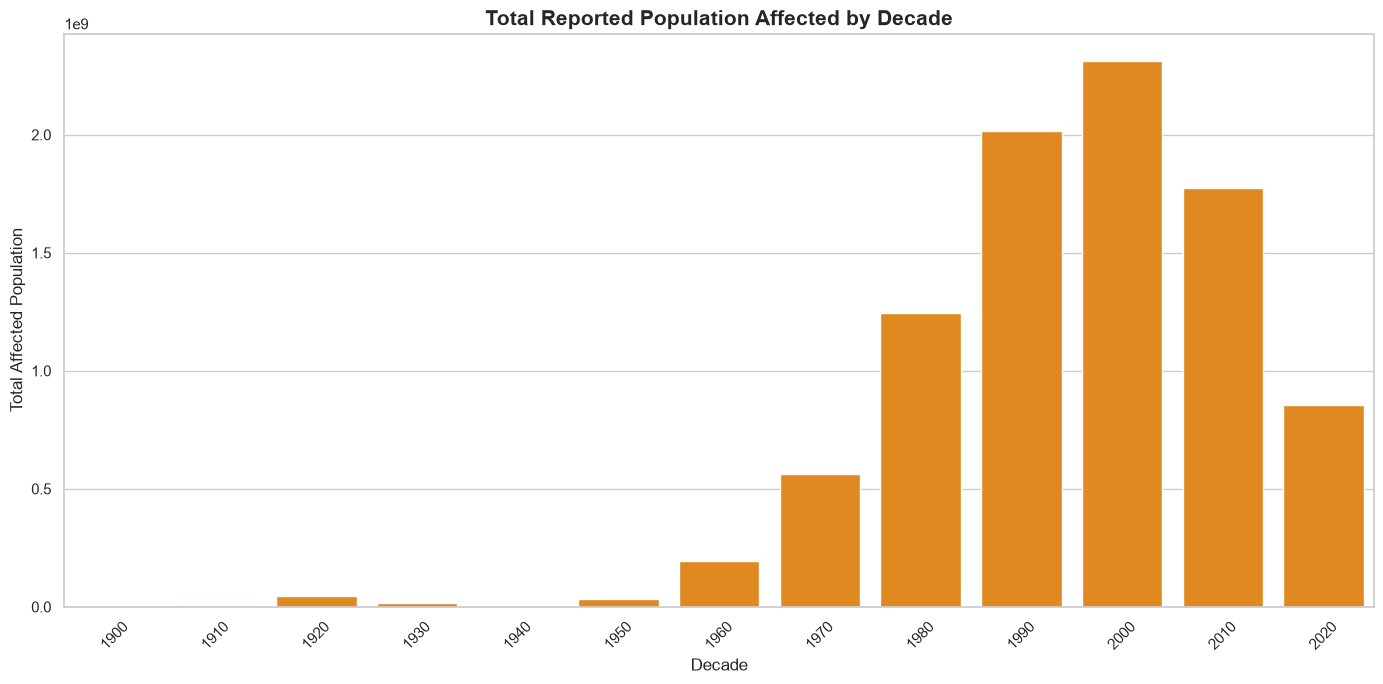

In [14]:
affected_data = decadal_impact.dropna(
    subset=["Total Affected"]
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=affected_data,
    x="Decade",
    y="Total Affected",
    color="darkorange"
)

plt.title(
    "Total Reported Population Affected by Decade",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Decade")
plt.ylabel("Total Affected Population")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    trend_dir / "04_decadal_affected_population.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
#economic damage across decades

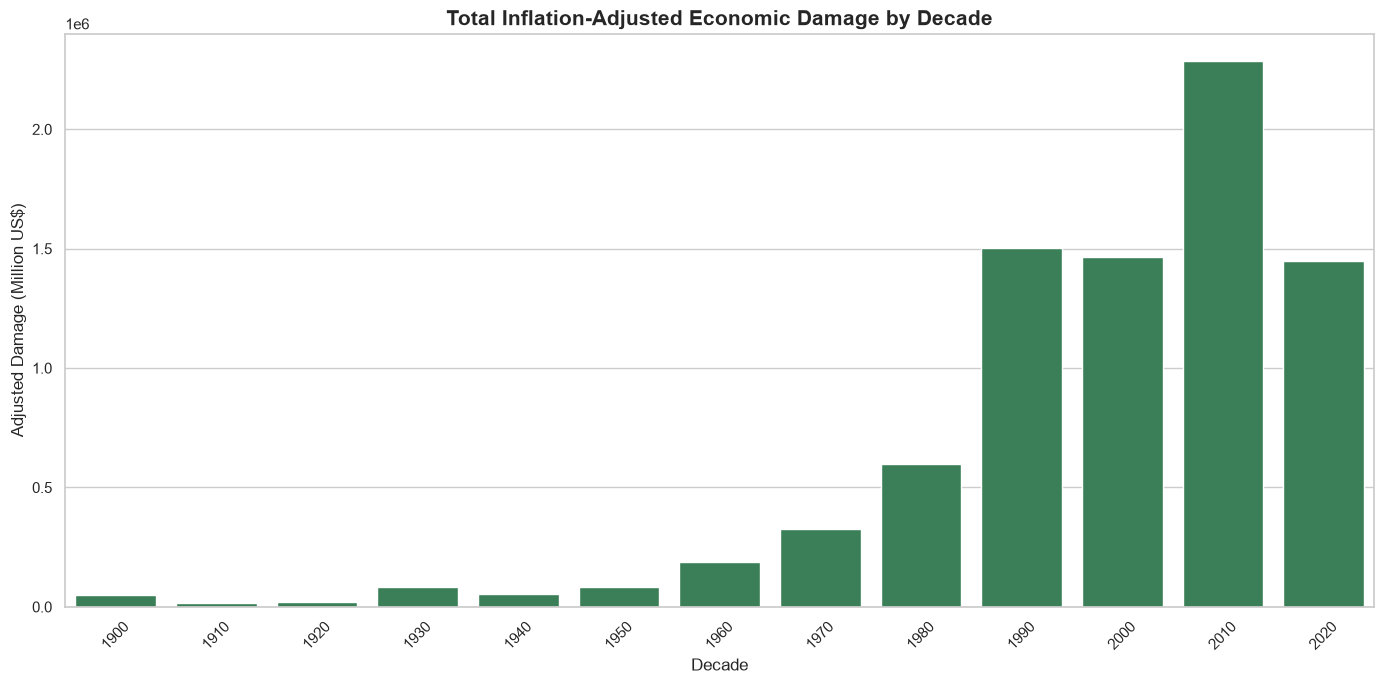

In [16]:
damage_data = decadal_impact.dropna(
    subset=["Total Adjusted Damage"]
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=damage_data,
    x="Decade",
    y="Total Adjusted Damage",
    color="seagreen"
)

plt.title(
    "Total Inflation-Adjusted Economic Damage by Decade",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Decade")
plt.ylabel("Adjusted Damage (Million US$)")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    trend_dir / "05_decadal_economic_damage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
decadal_impact["Death Coverage (%)"] = (
    decadal_impact["Reported Death Events"]
    / decadal_impact["Unique_Events"] * 100
)

decadal_impact["Affected Coverage (%)"] = (
    decadal_impact["Reported Affected Events"]
    / decadal_impact["Unique_Events"] * 100
)

decadal_impact["Damage Coverage (%)"] = (
    decadal_impact["Reported Damage Events"]
    / decadal_impact["Unique_Events"] * 100
)

display(
    decadal_impact[
        [
            "Decade",
            "Death Coverage (%)",
            "Affected Coverage (%)",
            "Damage Coverage (%)"
        ]
    ].round(2)
)

,Decade,Death Coverage (%),Affected Coverage (%),Damage Coverage (%)
0,1900,91.25,30.00,21.25
1,1910,86.11,29.17,20.83
2,1920,82.88,24.32,16.22
3,1930,88.81,32.84,17.91
4,1940,87.80,30.49,17.07
5,1950,92.60,32.15,20.90
6,1960,77.49,60.14,42.78
7,1970,72.39,69.57,37.25
8,1980,68.62,66.59,33.23
9,1990,72.30,77.94,37.63


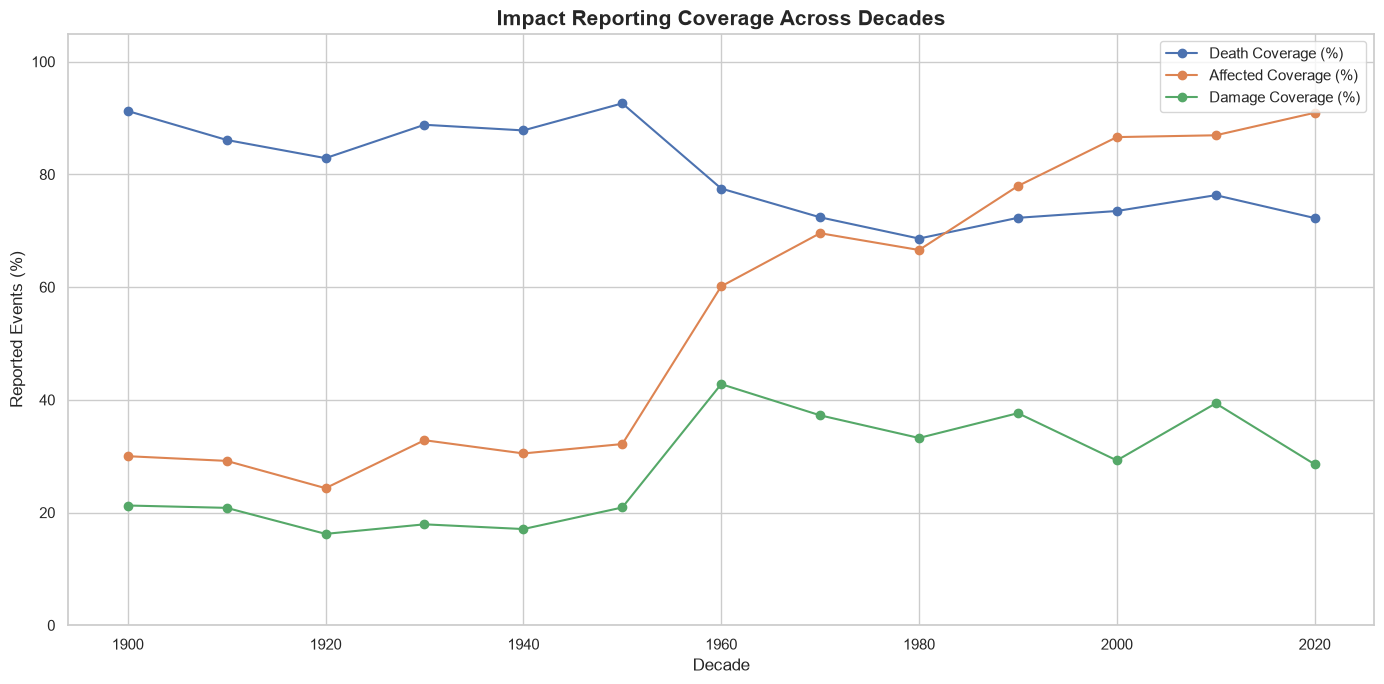

In [18]:
coverage_columns = [
    "Death Coverage (%)",
    "Affected Coverage (%)",
    "Damage Coverage (%)"
]

plt.figure(figsize=(14, 7))

for column in coverage_columns:
    plt.plot(
        decadal_impact["Decade"],
        decadal_impact[column],
        marker="o",
        label=column
    )

plt.title(
    "Impact Reporting Coverage Across Decades",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Decade")
plt.ylabel("Reported Events (%)")
plt.ylim(0, 105)
plt.legend()

plt.tight_layout()

plt.savefig(
    trend_dir / "06_decadal_reporting_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
#historical and recent periods

In [20]:
time_data["Period"] = np.where(
    time_data["Start Year"] < 2000,
    "Before 2000",
    "2000 Onwards"
)

period_comparison = (
    time_data.groupby("Period")
    .agg(
        Unique_Events=("Event ID", "nunique"),
        Reported_Deaths=("Total Deaths", "count"),
        Total_Deaths=("Total Deaths",
                      lambda x: x.sum(min_count=1)),
        Reported_Affected=("Total Affected", "count"),
        Total_Affected=("Total Affected",
                        lambda x: x.sum(min_count=1)),
        Reported_Damage=(
            "Total Damage, Adjusted (million US$)", "count"
        ),
        Total_Damage=(
            "Total Damage, Adjusted (million US$)",
            lambda x: x.sum(min_count=1)
        )
    )
    .reset_index()
)

display(period_comparison)

,Period,Unique_Events,Reported_Deaths,Total_Deaths,Reported_Affected,Total_Affected,Reported_Damage,Total_Damage
0,2000 Onwards,9017,6687,1738090.0,7915,4.940860e+09,2934,5202082.725
1,Before 2000,6710,4968,31104625.0,4451,4.124146e+09,2317,2918450.449


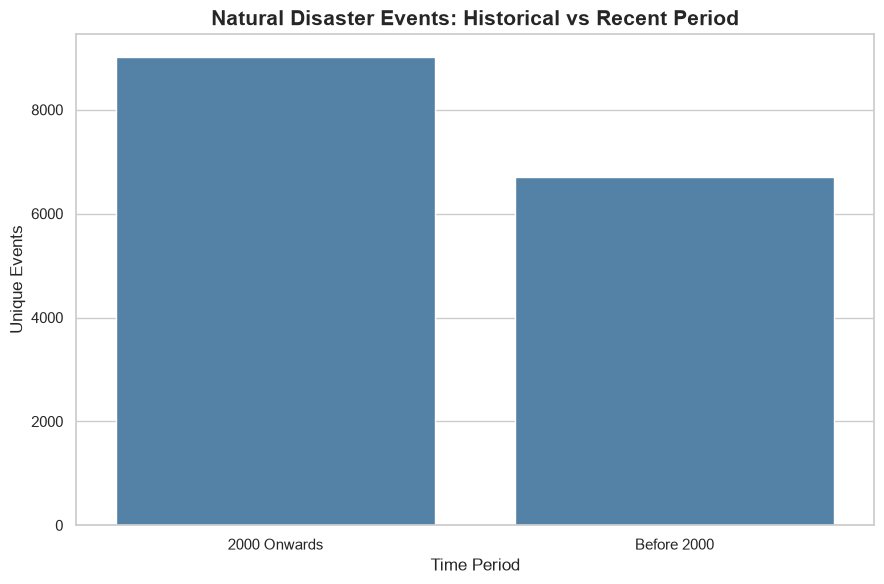

In [21]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=period_comparison,
    x="Period",
    y="Unique_Events",
    color="steelblue"
)

plt.title(
    "Natural Disaster Events: Historical vs Recent Period",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Time Period")
plt.ylabel("Unique Events")

plt.tight_layout()

plt.savefig(
    trend_dir / "07_historical_vs_recent.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
print("TEMPORAL ANALYSIS SUMMARY")

print(
    "\nHighest frequency year:",
    yearly_frequency.loc[
        yearly_frequency["Unique Events"].idxmax(),
        "Start Year"
    ]
)

print(
    "Maximum events in one year:",
    yearly_frequency["Unique Events"].max()
)

print(
    "\nHighest frequency decade:",
    top_decades.iloc[0]["Decade"]
)

print(
    "Maximum events in one decade:",
    top_decades.iloc[0]["Unique Events"]
)

print("\nDECADAL IMPACT SUMMARY")

display(
    decadal_impact[
        [
            "Decade",
            "Unique_Events",
            "Total Deaths",
            "Total Affected",
            "Total Adjusted Damage",
            "Death Coverage (%)",
            "Affected Coverage (%)",
            "Damage Coverage (%)"
        ]
    ].round(2)
)

TEMPORAL ANALYSIS SUMMARY

Highest frequency year: 2000
Maximum events in one year: 489

Highest frequency decade: 2000
Maximum events in one decade: 3744

DECADAL IMPACT SUMMARY


,Decade,Unique_Events,Total Deaths,Total Affected,Total Adjusted Damage,Death Coverage (%),Affected Coverage (%),Damage Coverage (%)
0,1900,80,4472682.0,6.211700e+05,50299.63,91.25,30.00,21.25
1,1910,72,3333790.0,6.341473e+06,14357.78,86.11,29.17,20.83
2,1920,111,8562465.0,4.457725e+07,19124.99,82.88,24.32,16.22
3,1930,134,4644783.0,1.603763e+07,81355.09,88.81,32.84,17.91
4,1940,164,3879024.0,3.505979e+06,51850.39,87.80,30.49,17.07
5,1950,311,2136187.0,3.429491e+07,83317.04,92.60,32.15,20.90
6,1960,582,1751443.0,1.955009e+08,189363.50,77.49,60.14,42.78
7,1970,851,998973.0,5.619404e+08,327487.62,72.39,69.57,37.25
8,1980,1676,797079.0,1.245482e+09,596644.40,68.62,66.59,33.23
9,1990,2729,528199.0,2.015844e+09,1504650.02,72.30,77.94,37.63


In [23]:
output_dir = ROOT / "analysis" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

yearly_frequency.to_csv(
    output_dir / "yearly_disaster_frequency.csv",
    index=False
)

decadal_frequency.to_csv(
    output_dir / "decadal_disaster_frequency.csv",
    index=False
)

decadal_impact.to_csv(
    output_dir / "decadal_disaster_impact.csv",
    index=False
)

period_comparison.to_csv(
    output_dir / "historical_recent_comparison.csv",
    index=False
)

print("Temporal analysis results exported successfully!")

Temporal analysis results exported successfully!
